### Make temporary directory

In [1]:
import os, random, string

In [2]:
cwd = os.path.basename(os.getcwd())
tmpdir = os.path.join("/flash/ReiterU/tmp/", 'tomo_' + ''.join(random.choices(string.ascii_uppercase, k=12)))
print(tmpdir)
if not os.path.exists(tmpdir):
    os.makedirs(tmpdir)

/flash/ReiterU/tmp/tomo_TLQRMHIBWBUY


### Main

In [9]:
import numpy as np
from matplotlib import pyplot as plt
import os
import subprocess
from scipy.stats import ttest_ind

In [4]:
from matplotlib import font_manager
import matplotlib as mpl
font_manager.fontManager.addfont('/bucket/ReiterU/common/fonts/arial.ttf')
mpl.rcParams.update({
    'font.size': 7,
    'axes.titlesize': 7,
    'legend.fontsize': 7,
    'font.family': 'sans-serif',
    'font.sans-serif': "Arial",
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.linewidth': 0.5,
    'xtick.major.width': 0.5,
    'xtick.major.size': 2,
    'xtick.minor.size': 2,
    'xtick.minor.width': 0.5,
    'ytick.major.width': 0.5,
    'ytick.minor.width': 0.5,
    'ytick.major.size': 2,
    'ytick.minor.size': 2,
    'xtick.major.pad': 2,
    'ytick.major.pad': 2,
    'axes.labelpad': 2
})

In [5]:
rootdir = "/bucket/ReiterU/OLdev/analysis/20250604_OGL_IGL_sponaneous_activity/"
datasets = [
    "20250520_rec10",
    # "20250522_rec11",
    "20250522_rec12",
    "20250523_rec3"
]

ogl_data = []
for f in datasets:
    d = np.loadtxt(os.path.join(rootdir, f, "OGL_spike_rate.csv"), delimiter=',')
    ogl_data.append(d)
ogl_data = np.concatenate(ogl_data)

igl_data = []
for f in datasets:
    d = np.loadtxt(os.path.join(rootdir, f, "IGL_spike_rate.csv"), delimiter=',')
    igl_data.append(d)
igl_data = np.concatenate(igl_data)

In [6]:
print(ogl_data.size, igl_data.size)

335 266


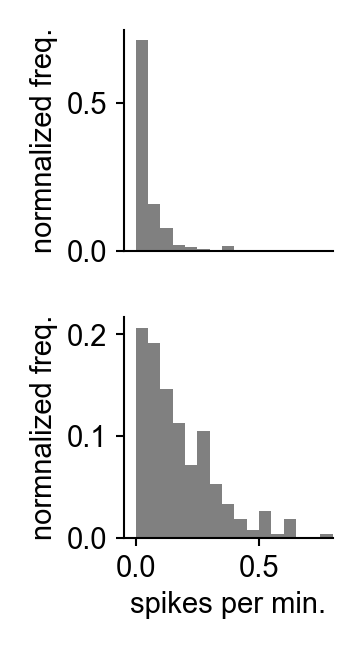

In [7]:
fig = plt.figure(figsize=(0.9,2.2), dpi=300)
gs = fig.add_gridspec(2, 1, hspace=0.3)

ogl_data = np.clip(ogl_data, 0, 0.8)
igl_data = np.clip(igl_data, 0, 0.8)

h_ogl, bin_edges = np.histogram(ogl_data, range=[0,0.8], bins=16, density=False)
h_igl, bin_edges = np.histogram(igl_data, range=[0,0.8], bins=16, density=False)
bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])

for i in range(2):
    ax = fig.add_subplot(gs[i, 0])
    if i == 0:
        h = h_ogl / h_ogl.sum()
        bar_color = "#51C2B8"
    elif i == 1:
        h = h_igl / h_igl.sum()
        bar_color = "#3A9DD7"
    bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])
    ax.bar(bin_centers, h, width=bin_edges[1]-bin_edges[0], align="center", lw=0, alpha=1, color="gray")
    ax.set_xlim(-0.05, 0.8)
    ax.set_ylabel("normnalized freq.")
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    if i == 0:
        ax.set_xticks([])
        ax.set_yticks([0, 0.5])
    if i == 1:
        ax.set_xlabel("spikes per min.")

plt.savefig(os.path.join(tmpdir, "spike_rates.pdf"), bbox_inches='tight')
plt.show()

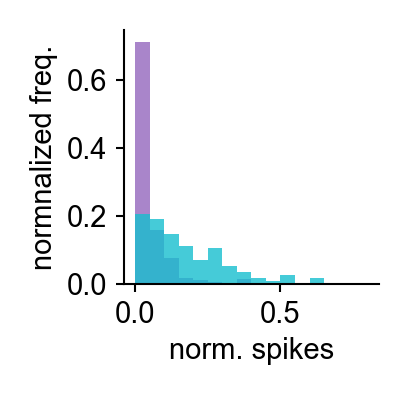

In [8]:
fig, ax = plt.subplots(figsize=(1.1, 1.1), dpi=300)

h_ogl, bin_edges = np.histogram(ogl_data, range=[0,0.8], bins=16, density=False)
h_igl, bin_edges = np.histogram(igl_data, range=[0,0.8], bins=16, density=False)
bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])

h_ogl = h_ogl / h_ogl.sum()
h_igl = h_igl / h_igl.sum()

ax.bar(bin_centers, h_ogl, width=bin_edges[1]-bin_edges[0], lw=0, alpha=0.8, label="OGL", color="#9467bd")
ax.bar(bin_centers, h_igl, width=bin_edges[1]-bin_edges[0], lw=0, alpha=0.8, label="IGL", color="#17becf")

ax.set_xlabel("norm. spikes")
ax.set_ylabel("normnalized freq.")
for sp in ["top", "right"]:
    ax.spines[sp].set_visible(False)
plt.savefig(os.path.join(tmpdir, "spike_rates2.pdf"), bbox_inches='tight')
plt.show()

In [10]:
t_stat, p_val = ttest_ind(ogl_data, igl_data, equal_var=False)  # Welch's t-test

print(f"T-statistic: {t_stat:.3f}")
print(f"P-value: {p_val:}")

T-statistic: -13.233
P-value: 1.0242662739545719e-32


In [12]:
print(np.median(ogl_data), np.median(igl_data))
print(np.mean(ogl_data), np.mean(igl_data))
print(np.std(ogl_data), np.std(igl_data))

0.0327 0.1308
0.043437014925373135 0.17115789473684212
0.0661732240798284 0.14564217027008833


In [16]:
savedir = "/bucket/ReiterU/OLdev/analysis/20250604_OGL_IGL_sponaneous_activity/"

cmd1 = f'ssh deigo "mkdir -p {savedir}"'
cmd2 = f'ssh deigo "cp -r {tmpdir}/* {savedir}"'
print(cmd1)
print(cmd2)

subprocess.run(cmd1, shell=True, check=True)
subprocess.run(cmd2, shell=True, check=True)

ssh deigo "mkdir -p /bucket/ReiterU/OLdev/analysis/20250604_OGL_IGL_sponaneous_activity/"
ssh deigo "cp -r /flash/ReiterU/tmp/tomo_YZCFUDJTDAQQ/* /bucket/ReiterU/OLdev/analysis/20250604_OGL_IGL_sponaneous_activity/"


Offending key for IP in /home/t/tomoyuki-mano1/.ssh/known_hosts:1
Matching host key in /home/t/tomoyuki-mano1/.ssh/known_hosts:6


CompletedProcess(args='ssh deigo "cp -r /flash/ReiterU/tmp/tomo_YZCFUDJTDAQQ/* /bucket/ReiterU/OLdev/analysis/20250604_OGL_IGL_sponaneous_activity/"', returncode=0)